# ESMFold2 — Missing density, complex context and template controls


## 1. Data source/acquisition

Download the fixed public analysis package. It contains MMseqs2 alignment hits, sequence clusters, cohort metadata, experimental C-alpha structures, model predictions and template-copy predictions. The cohort consists of160 protein entities released from2023-01-14, X-ray resolution≤3Å, length40–400, with40 entities per identity level. The search reference consists of PDB entries released before2021-09-30; search settings are sensitivity7.5, coverage0.8, coverage mode0.


In [1]:
from pathlib import Path
import os,json,hashlib,zipfile,urllib.request,io,socket
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
from IPython.display import display,Image
from Bio.SeqUtils import seq1
from tmtools import tm_align
DATA_ROOT=Path(os.environ.get('ESMFOLD_RELEASE_ROOT',str(Path.cwd()/'released-inputs')))
CALC_ROOT=Path(os.environ.get('ESMFOLD_CALC_ROOT',str(Path.cwd()/'calculations')))/'kimi-r2'
DATA_ROOT.mkdir(parents=True,exist_ok=True)
def sha256_file(path):
    digest=hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda:stream.read(1024*1024),b''):digest.update(block)
    return digest.hexdigest()
archive=DATA_ROOT/'esmfold2-inputs.zip'
source_url='https://github.com/shreyjain11/SPECTRAagent/releases/download/notebook-inputs-2026-11-08-v1/esmfold2-inputs.zip'
source_sha='c0c76766965d90de4128d0d3e11abadcf39f4acac8cff64c374657ee77172b24'
if not archive.is_file() or sha256_file(archive)!=source_sha:
    temporary=archive.with_suffix('.download')
    urllib.request.urlretrieve(source_url,temporary)
    if sha256_file(temporary)!=source_sha:raise ValueError('Public input archive fingerprint differs')
    temporary.replace(archive)
with zipfile.ZipFile(archive) as bundle:
    members=[m for m in bundle.infolist() if m.filename.startswith('assets/kimi-r2/audit/') and not m.is_dir() and not m.filename.endswith('.py')]
    for item in members:
        destination=(DATA_ROOT/item.filename).resolve()
        if DATA_ROOT.resolve() not in destination.parents:raise ValueError('Invalid archive member path')
        destination.parent.mkdir(parents=True,exist_ok=True)
        payload=bundle.read(item)
        if not destination.exists() or hashlib.sha256(destination.read_bytes()).digest()!=hashlib.sha256(payload).digest():destination.write_bytes(payload)
P=DATA_ROOT/'assets/kimi-r2/audit'
print('Verified public input archive:',source_url,'SHA256',source_sha)
print('Acquired data files:',len(members))


Verified public input archive: https://github.com/shreyjain11/SPECTRAagent/releases/download/notebook-inputs-2026-11-08-v1/esmfold2-inputs.zip SHA256 c0c76766965d90de4128d0d3e11abadcf39f4acac8cff64c374657ee77172b24
Acquired data files: 454


## 2. Data processing

Read the entity manifest, alignments and cluster assignments. Check disjoint pilot/expansion membership and unique40%-identity clusters. Extract experimental C-alpha positions and calculate observed-residue fraction; read the number of protein entities from the supplied RCSB entry metadata.


In [2]:
plan=pd.read_csv(P/'data/sample_plan_full.csv',usecols=['entity'])
pilot=pd.read_csv(P/'data/sample_plan.csv',usecols=['entity'])
expansion=pd.read_csv(P/'data/sample_plan_expansion.csv',usecols=['entity'])
candidates=pd.read_csv(P/'data/axis_table.csv',usecols=['entity','entry','length'])
clusters=pd.read_csv(P/'work_mmseqs/clus_cluster.tsv',sep='\t',header=None,names=['cluster','member'])
hits=pd.read_csv(P/'work_mmseqs/res.tsv',sep='\t',header=None,names=['query','target','fident','length','qcov','tcov','evalue','bits'])
confounds=json.loads((P/'data/entry_confounds.json').read_text())
if plan.entity.duplicated().any():raise ValueError('Duplicate evaluation entities')
if set(pilot.entity)&set(expansion.entity):raise ValueError('Pilot and expansion overlap')
if set(pilot.entity)|set(expansion.entity)!=set(plan.entity):raise ValueError('Evaluation split is incomplete')
cluster_of=dict(zip(clusters.member,clusters.cluster))
if len({cluster_of[x] for x in plan.entity})!=len(plan):raise ValueError('Evaluation units share a sequence cluster')
inputs=plan.merge(candidates,on='entity',validate='one_to_one')
inputs['split']=np.where(inputs.entity.isin(pilot.entity),'pilot','expansion')
def ca_coordinates(path):
    records=[line for line in Path(path).read_text().splitlines() if line.startswith('ATOM') and line[12:16].strip()=='CA']
    xyz=np.array([[float(line[30:38]),float(line[38:46]),float(line[46:54])] for line in records],dtype=np.float64)
    sequence=''.join(seq1(line[17:20],custom_map={'MSE':'M'}) for line in records)
    if len(xyz)==0:raise ValueError('No C-alpha coordinates: '+str(path))
    return xyz,sequence
structure_inputs={}
for row in inputs.itertuples():
    native,native_sequence=ca_coordinates(P/'results/exp'/f'{row.entity}.pdb')
    structure_inputs[row.entity]=(native,native_sequence)
inputs['observed_ca']=inputs.entity.map(lambda entity:len(structure_inputs[entity][0]))
inputs['observed_fraction']=inputs.observed_ca/inputs.length
inputs['protein_entities']=inputs.entry.map(lambda entry:confounds[entry]['prot_ent'])
display(inputs)
print('Evaluation targets:',len(inputs),'pilot:',len(pilot),'disjoint expansion:',len(expansion))


,entity,entry,length,split,observed_ca,observed_fraction,protein_entities
0,9KKU_1,9KKU,102,pilot,95,0.931373,2
1,7H0O_1,7H0O,170,pilot,167,0.982353,1
2,8QDZ_1,8QDZ,397,pilot,380,0.957179,1
3,8T8B_14,8T8B,112,pilot,110,0.982143,51
4,7U9W_1,7U9W,191,pilot,171,0.895288,2
...,...,...,...,...,...,...,...
155,9O6B_1,9O6B,101,expansion,61,0.603960,1
156,8RCW_1,8RCW,229,expansion,205,0.895197,1
157,24BX_1,24BX,327,expansion,322,0.984709,1
158,7YTU_2,7YTU,79,expansion,65,0.822785,2


Evaluation targets: 160 pilot: 32 disjoint expansion: 128


## 3. Axis definition and level construction

The axis is maximum identity among the supplied MMseqs2 hits, with0 for no hit. Levels are≥80%,40–80%,20–40% and<20%. Calculate values and levels directly from the hit table. Length strata are40–120,121–250 and251–400.


In [3]:
maximum_identity=hits.groupby('query').fident.max()
def identity_level(value):
    if value>=.80:return 'I1_ge80'
    if value>=.40:return 'I2_40_80'
    if value>=.20:return 'I3_20_40'
    return 'I4_lt20'
axis_values=inputs.copy()
axis_values['maximum_identity']=axis_values.entity.map(maximum_identity).fillna(0.0)
axis_values['level']=axis_values.maximum_identity.map(identity_level)
LEVELS=['I1_ge80','I2_40_80','I3_20_40','I4_lt20']
axis_values['level_number']=axis_values.level.map({level:i+1 for i,level in enumerate(LEVELS)})
axis_values['length_stratum']=pd.cut(axis_values.length,[39,120,250,400],labels=['S','M','L'])
if not axis_values.groupby('level').size().reindex(LEVELS).eq(40).all():raise ValueError('The evaluation does not contain40 targets at each identity level')
display(axis_values.groupby('level').agg(n=('entity','size'),identity_min=('maximum_identity','min'),identity_mean=('maximum_identity','mean'),identity_max=('maximum_identity','max'),mean_length=('length','mean')))
display(pd.crosstab(axis_values.level,axis_values.length_stratum))


,n,identity_min,identity_mean,identity_max,mean_length
level,,,,,
I1_ge80,40,0.871,0.960575,1.000,198.000
I2_40_80,40,0.405,0.615225,0.776,195.575
I3_20_40,40,0.210,0.319050,0.399,208.275
I4_lt20,40,0.000,0.000000,0.000,186.900


length_stratum,S,M,L
level,,,
I1_ge80,14,14,12
I2_40_80,14,14,12
I3_20_40,9,16,15
I4_lt20,14,14,12


## 4. Model results or released scores

The public package provides ESMFold2 coordinates generated with3 loops,50 diffusion steps,1 sample and seed0. This notebook calculates every TM-score from those coordinates and experimental structures. It also scores template-copy coordinates, where available, with normalization by experimental chain length. The visible inference function accepts a compatible standard Transformers ESMFold2 checkpoint for generating another structure; this evaluation uses the released predictions.


In [4]:
def predict_structure(sequence,checkpoint,device='cuda',seed=0):
    import torch
    from transformers import EsmFold2Model
    from transformers.models.esmfold2.protein_utils import prepare_protein_features,output_to_pdb
    model,loading=EsmFold2Model.from_pretrained(checkpoint,output_loading_info=True,dtype=torch.float32)
    failures={key:value for key,value in loading.items() if value and key in ['missing_keys','unexpected_keys','mismatched_keys','error_msgs','conversion_errors','skipped_pp_keys']}
    if failures:raise ValueError(f'Checkpoint loading failed: {failures}')
    model.esmc.to(torch.bfloat16)
    model=model.eval().to(device)
    torch.manual_seed(seed)
    if device.startswith('cuda'):torch.cuda.manual_seed_all(seed)
    features=prepare_protein_features(sequence,device=device)
    with torch.inference_mode():
        result=model.fold(**features,num_loops=3,num_sampling_steps=50,num_diffusion_samples=1)
    return output_to_pdb(result,features,sample_idx=0)

def score_coordinates(prediction,native):
    predicted_coords,predicted_sequence=ca_coordinates(prediction)
    native_coords,native_sequence=native
    alignment=tm_align(predicted_coords,native_coords,predicted_sequence,native_sequence)
    return {'tm':round(float(alignment.tm_norm_chain2),5),'rmsd':float(alignment.rmsd)}
scored_rows=[]
for row in axis_values.itertuples():
    native=structure_inputs[row.entity]
    model_score=score_coordinates(P/'results/pred'/f'{row.entity}.pdb',native)
    reference_path=P/'results/ref'/f'{row.entity}.pdb'
    reference_score=score_coordinates(reference_path,native) if reference_path.exists() else {'tm':np.nan,'rmsd':np.nan}
    scored_rows.append({'entity':row.entity,'tm_model':model_score['tm'],'rmsd_model':model_score['rmsd'],'tm_reference':reference_score['tm'],'rmsd_reference':reference_score['rmsd']})
measurements=axis_values.merge(pd.DataFrame(scored_rows),on='entity',validate='one_to_one')
if not np.isfinite(measurements.tm_model).all():raise ValueError('Missing model evaluation')
display(measurements[['entity','level','tm_model','tm_reference','rmsd_model','observed_fraction']])
print('Coordinate evaluations:',len(measurements),'model and',int(measurements.tm_reference.notna().sum()),'template reference')


,entity,level,tm_model,tm_reference,rmsd_model,observed_fraction
0,9KKU_1,I1_ge80,0.93599,0.95403,0.989478,0.931373
1,7H0O_1,I1_ge80,0.99504,0.99400,0.342866,0.982353
2,8QDZ_1,I1_ge80,0.99147,0.92511,0.663789,0.957179
3,8T8B_14,I1_ge80,0.97248,0.95605,0.674297,0.982143
4,7U9W_1,I1_ge80,0.70502,0.98044,3.183467,0.895288
...,...,...,...,...,...,...
155,9O6B_1,I4_lt20,0.92816,NaN,0.874809,0.603960
156,8RCW_1,I4_lt20,0.98035,NaN,0.865642,0.895197
157,24BX_1,I4_lt20,0.95548,NaN,1.452469,0.984709
158,7YTU_2,I4_lt20,0.30692,NaN,4.202779,0.822785


Coordinate evaluations: 160 model and 120 template reference


## 5. Curves and controls

Calculate means and95% Student-t intervals, the high-minus-low identity contrast, ordered Spearman association and the same measurements after observed-density and complex-context filtering. Test the disjoint128-target expansion separately. Template contrasts use only targets with a defined template prediction.


In [5]:
def mean_curve(frame):
    rows=[]
    for level in LEVELS:
        for label,column in [('ESMFold2','tm_model'),('Template reference','tm_reference')]:
            values=frame.loc[frame.level.eq(level),column].dropna().to_numpy(float)
            n=len(values)
            if n==0:continue
            mean=float(values.mean());half=float(stats.t.ppf(.975,n-1)*stats.sem(values)) if n>1 else np.nan
            rows.append({'level':level,'level_number':LEVELS.index(level)+1,'model':label,'n':n,'mean':mean,'lo':mean-half,'hi':mean+half})
    return pd.DataFrame(rows)
def draw_curve(table,title):
    fig,ax=plt.subplots(figsize=(7,4),layout='constrained')
    for label,group in table.groupby('model',sort=False):
        ax.errorbar(group.level_number,group['mean'],yerr=[group['mean']-group.lo,group.hi-group['mean']],marker='o',capsize=3,label=label)
    ax.set(xlabel='Identity level: high similarity → low similarity',ylabel='TM-score',title=title,xticks=[1,2,3,4]);ax.legend(frameon=False);ax.spines[['top','right']].set_visible(False)
    buffer=io.BytesIO();fig.savefig(buffer,format='png',dpi=140);plt.close(fig);display(Image(data=buffer.getvalue()))
def endpoint_and_trend(frame):
    high=frame.loc[frame.level.eq(LEVELS[0]),'tm_model'].to_numpy(float)
    low=frame.loc[frame.level.eq(LEVELS[-1]),'tm_model'].to_numpy(float)
    if min(len(high),len(low))<2:return {'n':len(frame),'high_n':len(high),'low_n':len(low),'high_minus_low':np.nan,'welch_p':np.nan,'rho':np.nan,'trend_p':np.nan}
    variance_high=high.var(ddof=1)/len(high);variance_low=low.var(ddof=1)/len(low)
    se=np.sqrt(variance_high+variance_low)
    dof=(variance_high+variance_low)**2/(variance_high**2/(len(high)-1)+variance_low**2/(len(low)-1))
    difference=high.mean()-low.mean();half=stats.t.ppf(.975,dof)*se
    trend=stats.spearmanr(frame.level_number,frame.tm_model)
    return {'n':len(frame),'high_n':len(high),'low_n':len(low),'high_minus_low':float(difference),'ci_lo':float(difference-half),'ci_hi':float(difference+half),'welch_p':float(stats.ttest_ind(high,low,equal_var=False).pvalue),'rho':float(trend.statistic),'trend_p':float(trend.pvalue)}
subsets={'All targets':measurements,'Observed fraction≥0.8':measurements[measurements.observed_fraction.ge(.8)],'Single protein entity':measurements[measurements.protein_entities.eq(1)],'Both filters':measurements[measurements.observed_fraction.ge(.8)&measurements.protein_entities.eq(1)],'Expansion only':measurements[measurements.split.eq('expansion')]}
control_results=pd.DataFrame([{'subset':name,**endpoint_and_trend(frame)} for name,frame in subsets.items()])
curves={name:mean_curve(frame) for name,frame in subsets.items()}
paired=[]
for level,group in measurements.dropna(subset=['tm_reference']).groupby('level'):
    differences=group.tm_model-group.tm_reference
    paired.append({'level':level,'n':len(group),'model_minus_reference':float(differences.mean()),'paired_p':float(stats.ttest_1samp(differences,0).pvalue)})
paired_results=pd.DataFrame(paired)
length_test=stats.kruskal(*[measurements.loc[measurements.level.eq(level),'length'] for level in LEVELS])
display(control_results);display(paired_results)
print('Length balance Kruskal–Wallis p:',float(length_test.pvalue))


,subset,n,high_n,low_n,high_minus_low,ci_lo,ci_hi,welch_p,rho,trend_p
0,All targets,160,40,40,0.086107,0.008701,0.163513,0.029857,-0.202609,0.010186
1,Observed fraction≥0.8,147,37,34,0.056924,-0.019547,0.133396,0.141352,-0.175616,0.033369
2,Single protein entity,118,21,31,0.128999,0.046011,0.211987,0.003284,-0.430355,0.000001
3,Both filters,111,21,25,0.087365,0.009712,0.165019,0.028782,-0.375963,0.000048
4,Expansion only,128,32,32,0.059810,-0.021700,0.141321,0.146802,-0.177013,0.045626


,level,n,model_minus_reference,paired_p
0,I1_ge80,40,-0.009256,6.349548e-01
1,I2_40_80,40,0.028922,2.377354e-01
2,I3_20_40,40,0.169855,1.197229e-11


Length balance Kruskal–Wallis p: 0.7433247554005702


,level,level_number,model,n,mean,lo,hi
0,I1_ge80,1,ESMFold2,37,0.914091,0.875660,0.952521
1,I1_ge80,1,Template reference,37,0.921424,0.872743,0.970105
2,I2_40_80,2,ESMFold2,37,0.911220,0.858397,0.964044
3,I2_40_80,2,Template reference,37,0.866853,0.830601,0.903105
4,I3_20_40,3,ESMFold2,39,0.935568,0.904178,0.966959
5,I3_20_40,3,Template reference,39,0.765262,0.736373,0.794151
6,I4_lt20,4,ESMFold2,34,0.857166,0.789858,0.924475


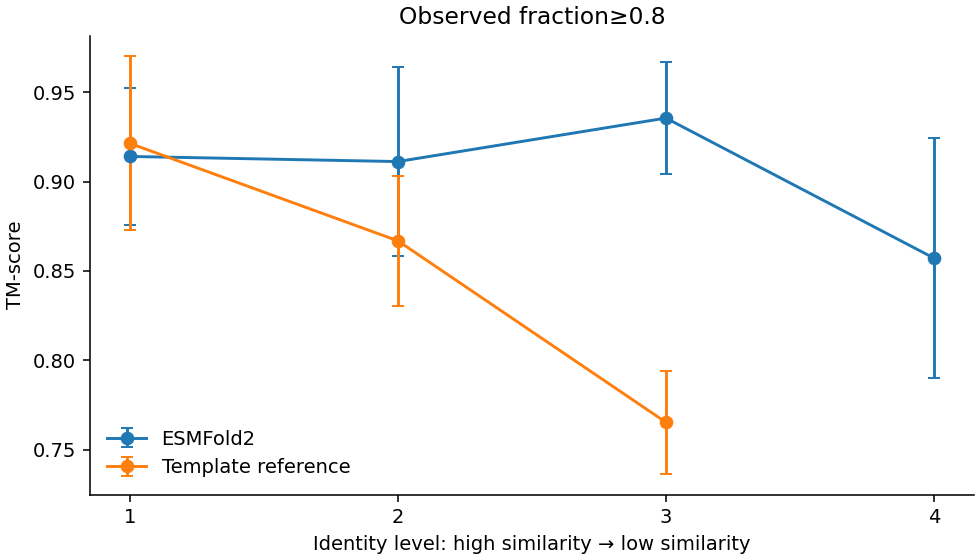

,level,level_number,model,n,mean,lo,hi
0,I1_ge80,1,ESMFold2,21,0.967498,0.943404,0.991592
1,I1_ge80,1,Template reference,21,0.955375,0.937904,0.972846
2,I2_40_80,2,ESMFold2,30,0.916074,0.851686,0.980462
3,I2_40_80,2,Template reference,30,0.867143,0.824354,0.909932
4,I3_20_40,3,ESMFold2,36,0.950530,0.935583,0.965477
5,I3_20_40,3,Template reference,36,0.767969,0.737847,0.798091
6,I4_lt20,4,ESMFold2,31,0.838499,0.758413,0.918586


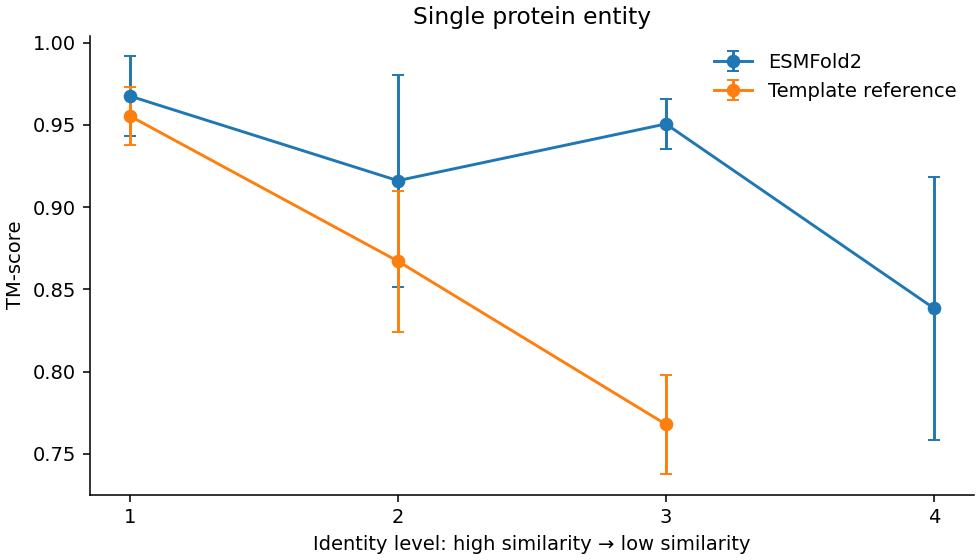

,level,level_number,model,n,mean,lo,hi
0,I1_ge80,1,ESMFold2,21,0.967498,0.943404,0.991592
1,I1_ge80,1,Template reference,21,0.955375,0.937904,0.972846
2,I2_40_80,2,ESMFold2,30,0.916074,0.851686,0.980462
3,I2_40_80,2,Template reference,30,0.867143,0.824354,0.909932
4,I3_20_40,3,ESMFold2,35,0.949919,0.934576,0.965263
5,I3_20_40,3,Template reference,35,0.766493,0.735619,0.797366
6,I4_lt20,4,ESMFold2,25,0.880133,0.805511,0.954755


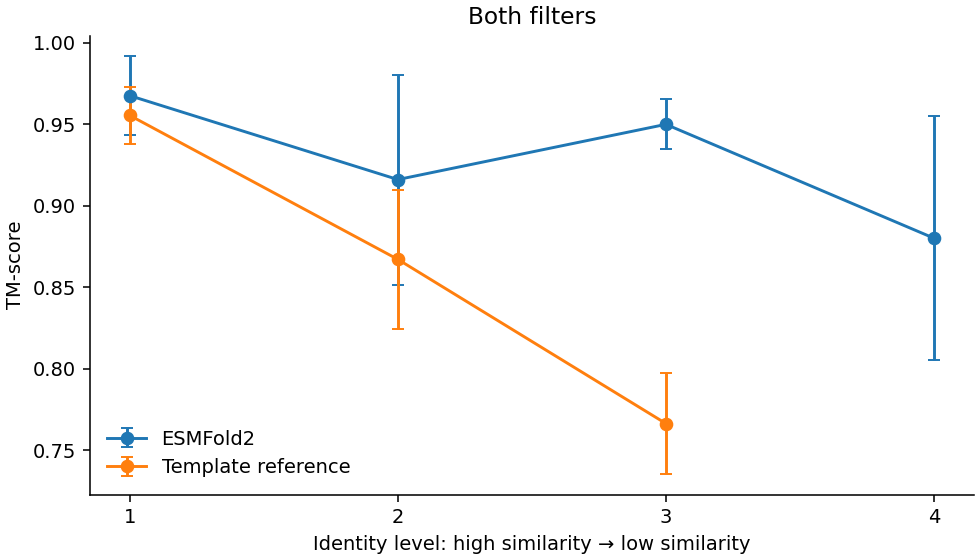

In [6]:
for name in ['Observed fraction≥0.8','Single protein entity','Both filters']:
    display(curves[name]);draw_curve(curves[name],name)


## 6. What the agent decided, and why

Use the calculated endpoint and trend tests to assess decreasing-identity performance, then distinguish the tested controls and template coverage.


In [7]:
primary=control_results.set_index('subset').loc['All targets']
criterion=bool(primary.high_minus_low>0 and primary.welch_p<.05 and primary.rho<0 and primary.trend_p<.05)
decision='Accept a decreasing-identity accuracy effect under the endpoint and trend criteria.' if criterion else 'The endpoint and trend criteria do not jointly support a decreasing-identity accuracy effect.'
print(decision)
print(f'High-minus-low TM-score={primary.high_minus_low:.5f}; Welch p={primary.welch_p:.4g}; ordered rho={primary.rho:.4f}, p={primary.trend_p:.4g}.')
model_means=curves['All targets'].query("model=='ESMFold2'").sort_values('level_number')['mean'].to_numpy()
print('Strictly decreasing level means:',bool(np.all(np.diff(model_means)<0)))
for row in control_results.itertuples():
    if row.subset!='All targets':print(row.subset,': endpoint decline supported' if row.high_minus_low>0 and row.welch_p<.05 else ': endpoint decline not supported at p<0.05')
print('The lowest-identity level has no template prediction; a four-level paired template contrast is undefined.')


Accept a decreasing-identity accuracy effect under the endpoint and trend criteria.
High-minus-low TM-score=0.08611; Welch p=0.02986; ordered rho=-0.2026, p=0.01019.
Strictly decreasing level means: False
Observed fraction≥0.8 : endpoint decline not supported at p<0.05
Single protein entity : endpoint decline supported
Both filters : endpoint decline supported
Expansion only : endpoint decline not supported at p<0.05
The lowest-identity level has no template prediction; a four-level paired template contrast is undefined.


In [8]:
output=CALC_ROOT/'test-02'
output.mkdir(parents=True,exist_ok=True)
inputs.to_csv(output/'input_features.csv',index=False);axis_values.to_csv(output/'axis_levels.csv',index=False);measurements.to_csv(output/'coordinate_scores.csv',index=False)
control_results.to_csv(output/'controls.csv',index=False);paired_results.to_csv(output/'paired_controls.csv',index=False)
for name,table in curves.items():table.to_csv(output/(name.lower().replace(' ','_').replace('≥','ge')+'_curve.csv'),index=False)
receipt={'analysis_id':'esmfold2-kimi-r2/test-02','completed':True,'host':socket.gethostname(),'input_archive_url':source_url,'input_archive_sha256':source_sha,'targets':len(measurements),'reference_targets':int(measurements.tm_reference.notna().sum()),'new_inference_executed':False,'calculation_scope':'alignment-derived axes, coordinate TM-scores, curves, statistical controls and decision','decision':decision}
(output/'CALCULATION_RECEIPT.json').write_text(json.dumps(receipt,indent=2))


637